In [111]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [112]:
import pandas as pd
import os
import glob
import shutil

import xarray as xr
import numpy as np
#from pyhomogenize import open_xrdataset
import seaborn as sns
#
import matplotlib as mpl
import matplotlib.pyplot as plt
import cftime
import xesmf as xe
import cordex as cx

In [113]:
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from plotting_tools_africa import plot_absolut

In [114]:
# The data needs to be regridded to the AFR-22 domain.
# Target Grid::
dm=cx.cordex_domain('AFR-22', bounds=True)

In [115]:
datadir='/work/ch0636/g300047/cicles/compound-events/results'
#testfile=datadir+'/compev_SU40_du3_TR26_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_2069-2098.nc'
#comeve_ds=xr.open_dataset(testfile, decode_times=False)

In [116]:
# Regrid each file's 'ev_coin_sdu' to AFR-22 grid and compute ensemble median per gridbox
def regrid_ensemble_median(inputfiles,dm, var='ev_coin_sdu'):
    '''first regrid to afr22 dm and afterwards calculate ensemle median
    input list of ensemble file
    output one dataset containing ensemble median
    '''

    ensemble_regridded = []

    for fp in inputfiles:
        print(f'Regridding: {os.path.basename(fp)}')
        ds = xr.open_dataset(fp, decode_timedelta=False)

        if var not in ds:
            print(f'  Skipped ({var} not found).')
            ds.close()
            continue

        #da_src = ds['ev_coin_sdu']
        # it needs to be annual, so each value needs to be divided by 30
        da_src = ds['ev_coin_sdu'] / 30.0

        # Use existing regridder if source grid matches, otherwise create/load per-file weights
        try:
            if 'lat' in ds and 'lon' in ds and 'lat' in comeve_ds and 'lon' in comeve_ds and \
                ds['lat'].shape == comeve_ds['lat'].shape and ds['lon'].shape == comeve_ds['lon'].shape:
                da_dst = regridder(da_src)
            else:
                src_id = os.path.splitext(os.path.basename(fp))[0]
                weight_file = os.path.join(weights_dir, f'w_{src_id}_to_AFR22_bilinear.nc')
                rg = xe.Regridder(ds, dm, method='bilinear', filename=weight_file, reuse_weights=False)
                da_dst = rg(da_src)
        finally:
            ds.close()

        ensemble_regridded.append(da_dst)

    if len(ensemble_regridded) == 0:
        raise RuntimeError('No regridded data available to compute ensemble median.')

    ev_coin_sdu_median = xr.concat(ensemble_regridded, dim='ensemble').median(dim='ensemble', skipna=True)
    ev_coin_sdu_median.name = 'ev_coin_sdu_median'

    return ev_coin_sdu_median

In [121]:
# Make desition what you want to plot:
#var_pattern='SU40_du3_TR26_du3'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>26°C]\nEvents Lasting at Least 3 Days"
#var_pattern='SU35_du3_DD_du5'
#title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#var_pattern='SU35_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_DD_du5'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#var_pattern='SU40_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_R50mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>50mm/day]\nEvents Lasting at Least 3 and 1 Days"
var_pattern='SU40_du3_TR_du3'
title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>20°C]\nEvents Lasting at Least 3 Days"

In [ ]:
#pattern='compev_SU40_*TR26_du3*rcp85*2069*.nc'
#inputfiles=glob.glob(os.path.join(datadir,pattern))
#compev_SU40_du3_TR26_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc


whole_ensemble_regridded=[]

for rcp in ['rcp26', 'rcp85']:
    print(f'rcp: {rcp}')
    for time_slice in ['1991-2020', '2031-2060', '2069-2098']:
        print(f'  time_slice: {time_slice}')
        pattern=f'compev_{var_pattern}*{rcp}*{time_slice}.nc'
        inputfiles=glob.glob(os.path.join(datadir,pattern))
        # Regrid and compute ensemble median for the variable 'ev_coin_sdu'
        outfile=f'ENSEMBLE/ev_coin_sdu_median_{var_pattern}_{rcp}_{time_slice}.nc'
        name=f'ev_coin_sdu_median_{rcp}_{time_slice}'
        name=regrid_ensemble_median(inputfiles,dm, var='ev_coin_sdu')
        outpath = os.path.join(datadir, outfile)
        name.to_dataset().to_netcdf(
            outpath,
            encoding={'ev_coin_sdu_median': {'zlib': True, 'complevel': 4}}
        )
        whole_ensemble_regridded.append(name)
        print(len(inputfiles))


rcp: rcp26
  time_slice: 1991-2020
Regridding: compev_SU40_du3_TR_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR_du3_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR_du3_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR26_du3_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR26_du3_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR26_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR26_du3_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_du3_TR26_du3_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_1991-2020.nc
Regridding: compev_SU40_d

In [119]:
sims_rcp26 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp26_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp26
sims_rcp85 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp85.sort()
sims_rcp85

['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_1991-2020.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_2031-2060.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_2069-2098.nc']

Selected colors, levels for plotting  ev_coin_sdu_median
['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp26_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp26_2031-2060.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp26_2069-2098.nc']
['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_2031-2060.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp85_2069-2098.nc']
sims_rcp26 ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3_TR26_du3_rcp26_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU40_du3

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:550: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png
/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png
Moving /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png -> /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU40_du3_TR_median_absolut_West_Africa_1200.png
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png
/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_West_Africa_1200.png
Moving /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin

'/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU40_du3_TR_median_absolut_West_Africa_1200.png'

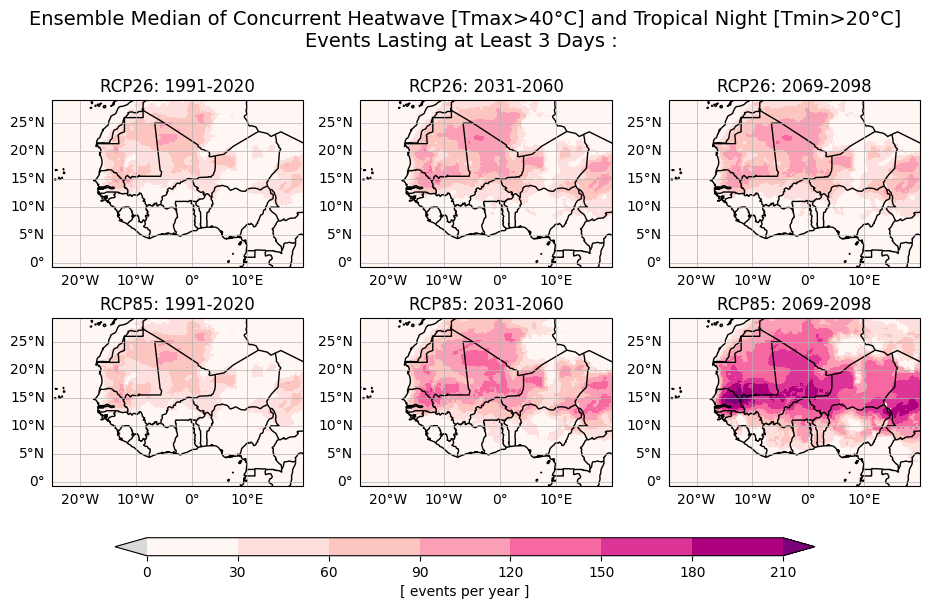

In [120]:
# plot
plot_dir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events'
var='ev_coin_sdu_median'
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_absolute(var)

# Now plot the absolute values
plot_absolut(
    sims_rcp26,
    sims_rcp85,
    level_steps, 
    color_steps,    
    plot_dir,
    title=title,
    var=var,
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
)

src=os.path.join(plot_dir,'ev_coin_sdu_median_absolut_West_Africa_1200.png')
print (src)
dst=os.path.join(plot_dir,var_pattern+'_median_absolut_West_Africa_1200.png')
print(f"Moving {src} -> {dst}")
shutil.move(src, dst)

